# 4. Resource estimation pipeline

In this tutorial, we demonstrate the full resource estimation pipeline using QUICHE. Furthermore, we perform a case study of when a certain simulation method is more advantageous than the others in terms of various metrics.

## 4.1. Hamiltonian simulation methods

We write the qubit Hamiltonian as a linear combination of Pauli strings, $H = \sum_{j=1}^{L} c_j P_j$, with 1-norm $\lambda = \sum_j |c_j|$. QPE needs controlled applications of the time-evolution operator $e^{-iHt}$ (or a unitary with the same eigenvectors), and the three methods below build it in different ways. In QUICHE, the evolution time is $t = \pi/\lambda$, so that the eigenphases $E_k t$ stay within $[-\pi, \pi]$.

Trotterisation and QDRIFT only approximate $e^{-iHt}$. We write $\epsilon_{\mathrm{sim}}$ for the simulation error, the largest error allowed in this approximation. It is the `simulation` entry of the `Errors` error budget.

- **Trotterisation** (`Simulation.Trotter`) [[Lloyd (1996)](https://doi.org/10.1126/science.273.5278.1073), [Suzuki (1991)](https://doi.org/10.1063/1.529425)]: Approximates $e^{-iHt}$ with a product of exponentials of the individual Pauli terms, $e^{-ic_jP_jt/r}$, repeated over $r$ time steps (a second-order product formula here). Each step costs about $L$ Pauli rotations. For a product formula of order $p$, QUICHE uses $r = \lceil ((\lambda t)^{p+1}/\epsilon_{\mathrm{sim}})^{1/p} \rceil$ steps, so for $p = 2$ the total cost scales as $\mathcal{O}(L\,\epsilon_{\mathrm{sim}}^{-1/2})$ rotations.

- **QDRIFT** (`Simulation.QDRIFT`) [[Campbell (2019)](https://doi.org/10.1103/PhysRevLett.123.070503)]: A randomised product formula that builds the evolution from $N$ Pauli rotations, sampling each term $P_j$ with probability $|c_j|/\lambda$. Each rotation is a single term, so the cost doesn't depend on $L$, but it needs $N = \lceil 2\lambda^2 t^2/\epsilon_{\mathrm{sim}} \rceil$ samples, which makes high precision expensive. With $t = \pi/\lambda$, this is $N = \lceil 2\pi^2/\epsilon_{\mathrm{sim}} \rceil$, whatever the Hamiltonian.

- **Qubitisation** (`Simulation.Qubitised`) [[Low and Chuang (2019)](https://doi.org/10.22331/q-2019-07-12-163), [Babbush et al. (2018)](https://doi.org/10.1103/PhysRevX.8.041015)]: Encodes $H/\lambda$ in a block of a larger unitary (a linear combination of unitaries (LCU) block encoding, built from PREPARE and SELECT oracles), then builds a quantum walk operator whose eigenphases are $\arccos(E_k/\lambda)$. There is no approximation error from splitting the exponential, and the cost is mostly Toffoli gates rather than arbitrary rotations. In exchange, it needs $\mathcal{O}(\log L)$ extra ancilla qubits, and each walk step costs $\mathcal{O}(L)$.

## 4.2. Setup

We fix the QPE method to be the textbook phase estimation method. Furthermore, we fix the fermion-to-qubit mapping to `Mapping.JordanWigner`. We vary the system size, i.e. `n_orb` with `n_elec = n_orb` for half filling, and the error budget.

The goal of this study is to answer which simulation method is cheapest, and what it costs in qubits for a given system size and target accuracy.

In [1]:
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.figure import Figure
from qualtran.resource_counting import GateCounts
from qualtran.surface_code import get_ccz2t_costs_from_grid_search
from random_hamiltonian import generate_random_sq_hamiltonian

from quiche import QPESpec
from quiche.core import (
    ElectronicHamiltonian,
    Errors,
    Mapping,
    PhaseEstimation,
    Simulation,
)
from quiche.resources.logical import (
    logical_gate_resources,
    logical_qubit_resources,
    logical_rotations_to_tgates,
)

# Fixed settings for the whole study.
QPE = PhaseEstimation.Textbook
MAPPING = Mapping.JordanWigner
SIMULATIONS = [Simulation.Trotter, Simulation.QDRIFT, Simulation.Qubitised]
SEED = 1

# Physical assumptions for the surface code cost model.
PHYS_ERR = 1e-3  # physical error rate per operation
CYCLE_TIME_US = 1.0  # surface code cycle time in microseconds
PHYS_ERROR_BUDGET = 1e-2  # allowed failure probability of the whole computation

# Use the same colour and marker for each method in every figure.
STYLE = {
    Simulation.Trotter.value: {"color": "tab:blue", "marker": "o"},
    Simulation.QDRIFT.value: {"color": "tab:orange", "marker": "s"},
    Simulation.Qubitised.value: {"color": "tab:green", "marker": "^"},
}

## 4.3. Metrics

For each calculation, we build the full QPE circuit as a Qualtran bloq with `QPESpec.get_composite_bloq()` and compute the following metrics.

**Logical metrics** (fault-tolerant gate counts, independent of the hardware):

- **Logical qubits**: The maximum number of logical qubits in use at any point of the circuit.
- **Toffoli count**: The number of Toffoli and AND gates. Qubitisation is built mostly from these.
- **T count**: The number of T gates, counting 4 T gates per Toffoli or AND gate. Trotterisation and QDRIFT are built almost entirely from arbitrary-angle $R_z$ rotations, which must first be synthesised into T gates. We use `logical_rotations_to_tgates`, which spends about $3\log_2(N_{\mathrm{rot}}/\epsilon_{\mathrm{rot}})$ T gates per rotation, where $N_{\mathrm{rot}}$ is the number of rotations and $\epsilon_{\mathrm{rot}}$ is the `rotations` entry of the error budget, shared equally between the rotations. This is the cost of approximating a single-qubit rotation to within $\epsilon_{\mathrm{rot}}/N_{\mathrm{rot}}$ with Clifford and T gates [[Ross and Selinger (2016)](https://arxiv.org/abs/1403.2975)]. Without this conversion, Trotterisation and QDRIFT would look artificially cheap.

**Physical metrics** (for surface code):

- **Physical qubits**: The number of physical qubits for the data block and the magic state factories.
- **Runtime**: The wall-clock time to run the algorithm once.
- **Spacetime volume**: Physical qubits $\times$ runtime, in qubit-hours. A method can trade qubits for time, so this single number makes the methods easier to compare.

For the physical metrics, we use the CCZ $\to$ 2T factory model of [Gidney and Fowler (2019)](https://doi.org/10.22331/q-2019-04-30-135) as implemented in `qualtran.surface_code`. `get_ccz2t_costs_from_grid_search` searches over magic state factories and code distances and returns the layout with the smallest spacetime volume. It fails when no factory in its search space is good enough for the requested number of T gates, so we record those cases as missing data. We assume a physical error rate of $10^{-3}$ and a surface code cycle time of $1\,\mu\mathrm{s}$, which are common assumptions for superconducting qubits [[Fowler et al. (2012)](https://doi.org/10.1103/PhysRevA.86.032324), [Gidney and Ekerå (2021)](https://doi.org/10.22331/q-2021-04-15-433)], and allow the whole computation to fail with probability $10^{-2}$.

In [2]:
def get_physical_resources(gates: GateCounts, n_qubits: int) -> dict[str, float]:
    """Physical surface code costs, or NaNs if no valid layout exists."""
    try:
        cost, _, _ = get_ccz2t_costs_from_grid_search(
            n_logical_gates=gates,
            n_algo_qubits=n_qubits,
            phys_err=PHYS_ERR,
            error_budget=PHYS_ERROR_BUDGET,
            cycle_time_us=CYCLE_TIME_US,
        )
    except ValueError:
        # No magic state factory is reliable enough for this many T gates.
        return {
            "physical_qubits": np.nan,
            "runtime_hr": np.nan,
            "spacetime_qubit_hr": np.nan,
        }

    return {
        "physical_qubits": cost.footprint,
        "runtime_hr": cost.duration_hr,
        "spacetime_qubit_hr": cost.qubit_hours,
    }


def estimate_resources(
    ham: ElectronicHamiltonian, simulation: Simulation, errors: Errors
) -> dict[str, Any]:
    """Logical and physical resource estimates for a single QPE calculation."""
    spec = QPESpec(
        hamiltonian=ham,
        state_prep=None,
        algorithm=QPE,
        simulation=simulation,
        error_budget=errors,
        seed=SEED,
    )
    bloq = spec.get_composite_bloq()

    # Logical resource estimates, with the rotations synthesised into T gates.
    gates = logical_gate_resources(bloq)
    gates_t = logical_rotations_to_tgates(gates, errors, rotation_synthesis="direct")
    n_qubits = logical_qubit_resources(bloq)

    return {
        "method": simulation.value,
        "num_terms": ham.paulis.num_words,
        "logical_qubits": n_qubits,
        "rotations": gates.rotation,
        "toffoli": gates_t.toffoli + gates_t.and_bloq,
        "t_count": gates_t.total_t_count(),
        **get_physical_resources(gates_t, n_qubits),
    }


def plot_metrics(
    df: pd.DataFrame, x: str, xlabel: str, *, logx: bool = False
) -> tuple[Figure, np.ndarray]:
    """Plot the logical (top row) and physical (bottom row) metrics against x."""
    metrics = [
        ("logical_qubits", "Logical qubits"),
        ("toffoli", "Toffoli count"),
        ("t_count", "T count"),
        ("physical_qubits", "Physical qubits"),
        ("runtime_hr", "Runtime (hours)"),
        ("spacetime_qubit_hr", "Spacetime volume (qubit-hours)"),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
    for ax, (metric, label) in zip(axes.flat, metrics, strict=True):
        for simulation in SIMULATIONS:
            group = df[df["method"] == simulation.value]
            ax.plot(
                group[x],
                group[metric],
                label=simulation.value,
                **STYLE[simulation.value],
            )
        ax.set_ylabel(label)
        ax.set_yscale("log" if metric != "logical_qubits" else "linear")
        if logx:
            ax.set_xscale("log")
        ax.grid(visible=True, which="major", alpha=0.3)
    for ax in axes[1]:
        ax.set_xlabel(xlabel)
    axes[0, 0].legend()
    fig.tight_layout()
    return fig, axes

## 4.4. Cost vs. system size

First, we fix the error budget and increase the number of spatial orbitals from 1 to 8 (2 to 16 qubits). The Hamiltonians are random, with dense one- and two-body integrals, so the number of Pauli terms $L$ grows roughly as $N^4$.

In [3]:
errors = Errors(
    estimation=1e-2, simulation=1e-3, rotations=1e-3, state_prep=1e-3, overlap=0.9
)

rng = np.random.default_rng(SEED)
rows = []
for n_orb in range(1, 9):
    sq_ham = generate_random_sq_hamiltonian(n_orb=n_orb, n_elec=n_orb, rng=rng)
    ham = sq_ham.to_qubit_hamiltonian(mapping=MAPPING)
    rows.extend(
        {"n_orb": n_orb, **estimate_resources(ham, simulation, errors)}
        for simulation in SIMULATIONS
    )

df_size = pd.DataFrame(rows)
df_size.set_index(["n_orb", "method"])

num_terms  logical_qubits    rotations   toffoli  \
n_orb method                                                        
1     trotter            3              15      8701920        66   
      qdrift             3              15    161674740        66   
      qubitised          3              43           45    145497   
2     trotter           26              17     75384900        66   
      qdrift            26              17    161674740        66   
      qubitised         26              55           45    610459   
3     trotter          117              19    339217560        66   
      qdrift           117              19    161674740        66   
      qubitised        117              61           45   2072775   
4     trotter          360              21   1043737740        66   
      qdrift           360              21    161674740        66   
      qubitised        360              69           45   4305139   
5     trotter          875              23   2536856640        66   
      qdrift           875              23    161674740        66   
      qubitised        875              73           45  13429001   
6     trotter         1818              25   5270858820        66   
      qdrift          1818              25    161674740        66   
      qubitised       1818              77           45  18120991   
7     trotter         3381              27   9802402200        66   
      qdrift          3381              27    161674740        66   
      qubitised       3381              81           45  50698549   
8     trotter         5792              29  16792518060        66   
      qdrift          5792              29    161674740        66   
      qubitised       5792              85           45  57307467   

                       t_count  physical_qubits    runtime_hr  \
n_orb method                                                    
1     trotter        861490354         184510.0     27.220697   
      qdrift       17945896414         214894.0    567.040472   
      qubitised         584068         145330.0      0.006052   
2     trotter       8141569474         207604.0    257.250975   
      qdrift       17945896414         222452.0    567.040472   
      qubitised        2443916         180934.0      0.025232   
3     trotter      38670802114         248186.0   1361.534486   
      qdrift       17945896414         228218.0    567.040472   
      qubitised        8293180         211960.0      0.098227   
4     trotter     124204791334         269824.0   4373.043690   
      qdrift       17945896414         233984.0    567.040472   
      qubitised       17222636         230288.0      0.203954   
5     trotter     312033366994         307078.0  12112.961949   
      qdrift       17945896414         239750.0    567.040472   
      qubitised       53718084         257756.0      0.636071   
6     trotter     664128211594              NaN           NaN   
      qdrift       17945896414         245516.0    567.040472   
      qubitised       72486044         265256.0      0.858288   
7     trotter    1264509884074              NaN           NaN   
      qdrift       17945896414         251282.0    567.040472   
      qubitised      202796276         298132.0      2.401198   
8     trotter    2199819866134              NaN           NaN   
      qdrift       17945896414         265240.0    567.040472   
      qubitised      229231948         313024.0      2.714204   

                 spacetime_qubit_hr  
n_orb method                         
1     trotter          5.022491e+06  
      qdrift           1.218536e+08  
      qubitised        8.796028e+02  
2     trotter          5.340633e+07  
      qdrift           1.261393e+08  
      qubitised        4.565351e+03  
3     trotter          3.379138e+08  
      qdrift           1.294088e+08  
      qubitised        2.082022e+04  
4     trotter          1.179952e+09  
      qdrift           1.326784e+08  
      qubitised        4.696825e+04  

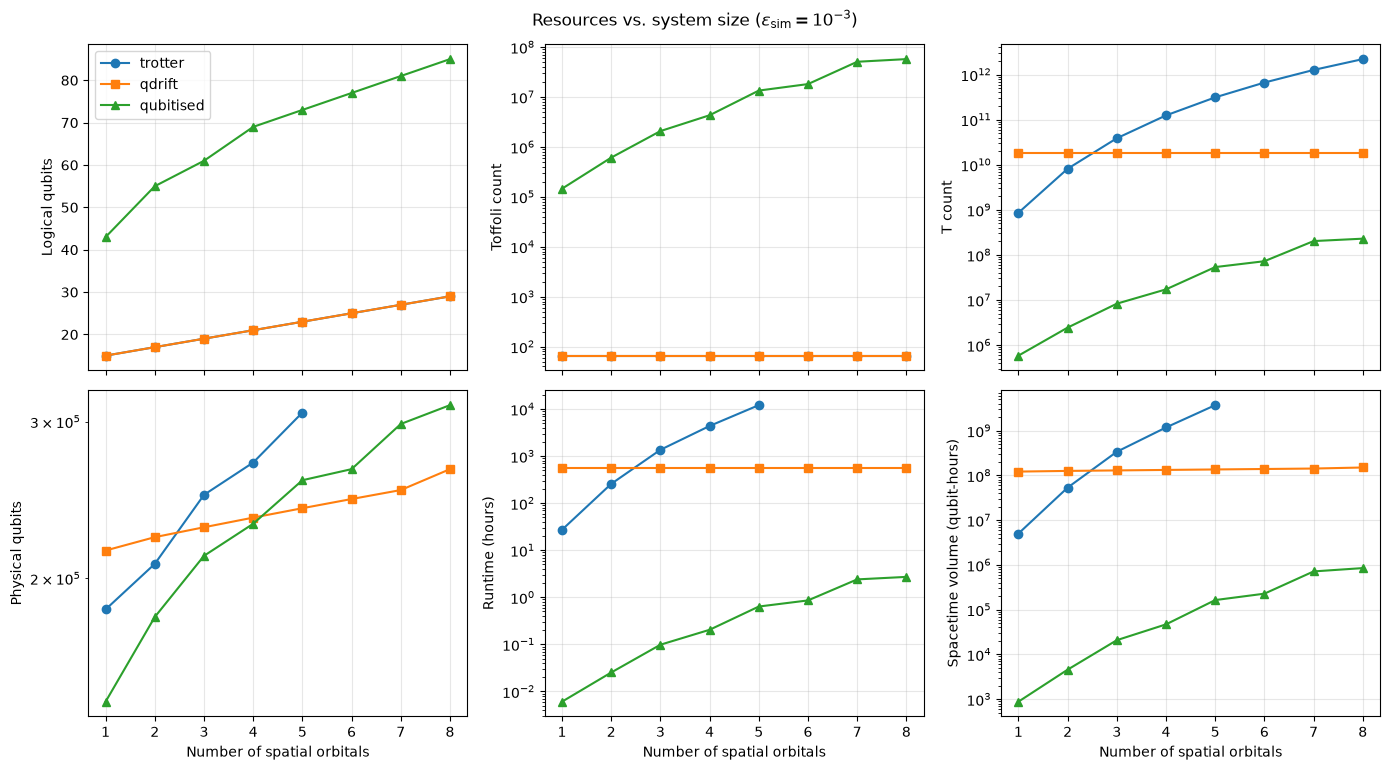

In [4]:
fig, axes = plot_metrics(df_size, x="n_orb", xlabel="Number of spatial orbitals")
fig.suptitle(r"Resources vs. system size ($\epsilon_{\mathrm{sim}} = 10^{-3}$)", y=1.02)
plt.show()

A few things to notice:

- **QDRIFT** has a constant T count of about $1.8\times10^{10}$ at every system size. The number of samples depends only on $\epsilon_{\mathrm{sim}}$, and each sample is a single rotation, however many terms the Hamiltonian has.
- **Trotterisation** costs about $L$ rotations per step, so its T count grows with the number of terms, from $8.6\times10^{8}$ to $2.2\times10^{12}$. It is cheaper than QDRIFT for the smallest systems, but QDRIFT is cheaper from `n_orb = 3` onwards. From `n_orb = 6`, no magic state factory in the search space can produce more than $5\times10^{11}$ T gates within the error budget, so the physical metrics are missing.
- **Qubitisation** has the lowest T count at every size, from $5.8\times10^{5}$ to $2.3\times10^{8}$. That is about $1500\times$ fewer T gates than Trotterisation at `n_orb = 1`, but only about $80\times$ fewer than QDRIFT at `n_orb = 8`, because its T count grows with the number of terms and QDRIFT's doesn't. Its runtime stays below about 3 hours, while QDRIFT takes about 570 hours.
- The price of qubitisation is about $3\times$ more logical qubits (43 to 85, vs. 15 to 29) for the block encoding registers. The physical qubit counts are similar for all three methods, because the magic state factories dominate the physical footprint.
- Trotterisation and QDRIFT have the same logical qubit counts, so their lines overlap. Their Toffoli count of 66 comes from the inverse QFT, which all three methods share.

## 4.5. Cost vs. target accuracy

Next, we fix the system size at `n_orb = 3` and tighten the error budget. Each method spends its error budget differently:

- Trotterisation and QDRIFT use `simulation` to set the number of time steps or samples.
- Qubitisation has no simulation error, but uses `state_prep` to set the size of the register that stores the PREPARE rotation angles.

For a fair comparison, we set both `simulation` and `state_prep` to the same $\epsilon$ and keep the other entries of the budget fixed.

In [5]:
n_orb = 3
rng = np.random.default_rng(SEED)
sq_ham = generate_random_sq_hamiltonian(n_orb=n_orb, n_elec=n_orb, rng=rng)
ham = sq_ham.to_qubit_hamiltonian(mapping=MAPPING)

rows = []
for eps in np.logspace(-1, -6, 11):
    errors = Errors(
        estimation=1e-2, simulation=eps, rotations=1e-3, state_prep=eps, overlap=0.9
    )
    for simulation in SIMULATIONS:
        rows.append({"epsilon": eps, **estimate_resources(ham, simulation, errors)})

df_eps = pd.DataFrame(rows)
df_eps.set_index(["epsilon", "method"])

num_terms  logical_qubits     rotations  toffoli  \
epsilon  method                                                        
0.100000 trotter          117              19      34500420       66   
         qdrift           117              19       1625760       66   
         qubitised        117              49            45  1876167   
0.031623 trotter          117              19      61330860       66   
         qdrift           117              19       5122890       66   
         qubitised        117              51            45  1908935   
0.010000 trotter          117              19     107325900       66   
         qdrift           117              19      16171200       66   
         qubitised        117              55            45  1974471   
0.003162 trotter          117              19     191650140       66   
         qdrift           117              19      51134310       66   
         qubitised        117              59            45  2040007   
0.001000 trotter          117              19     339217560       66   
         qdrift           117              19     161674740       66   
         qubitised        117              61            45  2072775   
0.000316 trotter          117              19     601772580       66   
         qdrift           117              19     511232130       66   
         qubitised        117              65            45  2138311   
0.000100 trotter          117              19    1067472360       66   
         qdrift           117              19    1616652810       66   
         qubitised        117              69            45  2203847   
0.000032 trotter          117              19    1899216000       66   
         qdrift           117              19    5112275850       66   
         qubitised        117              71            45  2236615   
0.000010 trotter          117              19    3374890200       66   
         qdrift           117              19   16166417130       66   
         qubitised        117              75            45  2302151   
0.000003 trotter          117              19    6002356860       66   
         qdrift           117              19   51122688480       66   
         qubitised        117              79            45  2367687   
0.000001 trotter          117              19   10672769880       66   
         qdrift           117              19  161664125850       66   
         qubitised        117              81            45  2400455   

                           t_count  physical_qubits    runtime_hr  \
epsilon  method                                                     
0.100000 trotter        3622544374         206410.0    114.462335   
         qdrift          147944434         162650.0      4.140385   
         qubitised         7506748         197396.0      0.077443   
0.031623 trotter        6562402294         206410.0    207.353679   
         qdrift          491797714         193258.0     15.539437   
         qubitised         7637820         211018.0      0.078794   
0.010000 trotter       11698523374         220538.0    369.640838   
         qdrift         1633291474         199754.0     51.607469   
         qubitised         7899964         202438.0      0.093571   
0.003162 trotter       21464815954         241226.0    755.740390   
         qdrift         5420237134         206410.0    171.264432   
         qubitised         8162108         208786.0      0.096675   
0.001000 trotter       38670802114         248186.0   1361.534486   
         qdrift        17945896414         228218.0    567.040472   
         qubitised         8293180         211960.0      0.098227   
0.000316 trotter       70407392134         248186.0   2478.926926   
         qdrift        59302927354         248186.0   2087.957229   
         qubitised         8555324         218308.0      0.101331   
0.000100 trotter      127029211114         263290.0   4472.486803   
         qdrift       195614990284         271482.

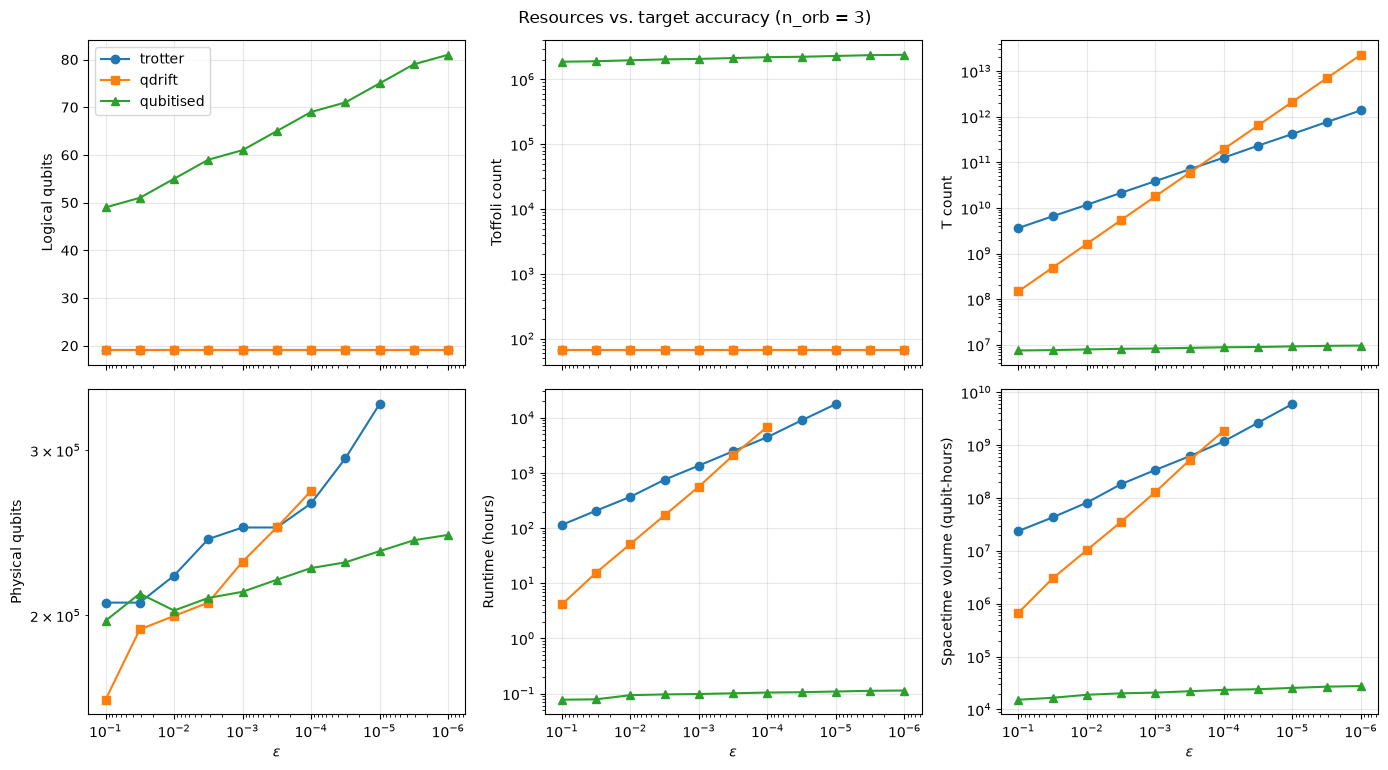

In [6]:
fig, axes = plot_metrics(df_eps, x="epsilon", xlabel=r"$\epsilon$", logx=True)
axes[0, 0].invert_xaxis()  # higher accuracy to the right (shared by all panels)
fig.suptitle(f"Resources vs. target accuracy (n_orb = {n_orb})", y=1.02)
plt.show()

The slopes of the T count match the scalings from Section 4.1:

- **QDRIFT** grows as $\epsilon^{-1}$, from $1.5\times10^{8}$ to $2.3\times10^{13}$ over five decades of $\epsilon$.
- **Trotterisation** grows as $\epsilon^{-1/2}$, from $3.6\times10^{9}$ to $1.4\times10^{12}$.
- The two lines cross between $\epsilon = 3\times10^{-4}$ and $10^{-4}$. QDRIFT is cheaper at low accuracy and Trotterisation is cheaper at high accuracy.
- **Qubitisation** is almost independent of $\epsilon$. Its T count grows by only about $30\%$, from $7.5\times10^{6}$ to $9.6\times10^{6}$, because a tighter budget only adds qubits to the PREPARE angle register, which grows as $\log(1/\epsilon)$. This shows up as the logical qubit count growing from 49 to 81.
- From $\epsilon \approx 3\times10^{-5}$ (QDRIFT) and $3\times10^{-6}$ (Trotterisation) downwards, the product formulas need too many T gates to fit the error budget, so their physical metrics are missing.

## 4.6. Takeaways

- **Qubitisation** has the lowest T count, runtime and spacetime volume everywhere in this study, with between about $20\times$ and over $10^{6}\times$ fewer T gates than the product formulas. Its advantage grows with accuracy, but shrinks with system size against QDRIFT, whose cost doesn't depend on the number of terms. The price is about $3\times$ more logical qubits. In physical qubits the extra cost is small, because the magic state factories dominate the footprint.
- **QDRIFT** is the better product formula for large Hamiltonians at low accuracy, since its cost doesn't depend on the number of terms.
- **Trotterisation** is the better product formula for small Hamiltonians or high accuracy.

These results come with some caveats:

- The Trotter step count uses a bound in $\lambda^{p+1}$ instead of a commutator bound [[Childs et al. (2021)](https://doi.org/10.1103/PhysRevX.11.011020)], so it is pessimistic.
- The product formula T counts are dominated by rotation synthesis. A cheaper synthesis method would narrow, but not close, the gap.
- The random Hamiltonians have dense integrals, so real molecules have fewer terms at the same size. A more compact block encoding, such as DF-THC, would make qubitisation cheaper still.